# 02. Pré-processamento

Aqui transformamos cada face anotada em uma entrada que o modelo consegue usar, tomando
cuidado para que os pontos continuem no lugar certo depois de cada transformação.

O caminho é este:

1. Recortar a face num quadrado e saber desfazer esse recorte
2. Escolher a margem do recorte
3. Ver quantos pixels sobram para os olhos
4. Separar treino e validação
5. Fazer data augmentation sem bagunçar os pontos (com o `Mirror98.txt`)
6. Salvar os recortes num cache, que é a saída deste notebook, usada pelo `04_treino` e pelo `05_avaliacao`

Tudo o que é gerado fica em `data/processed/`:

| Arquivo | Conteúdo |
|---|---|
| `train_crops.npy` e `test_crops.npy` | os recortes de 384 por 384 pixels de cada face, com folga para o augmentation |
| `train_meta.npz` e `test_meta.npz` | os pontos no recorte e na imagem original, retângulos, atributos e matrizes |
| `split.npz` | quais faces ficam no treino e quais ficam na validação |

In [1]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 90
SEED = 42

# raiz do projeto (o notebook roda de dentro de notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"                      # WFLW (espelho público no Kaggle, ver o README)
ANN, IMG = DATA / "WFLW_annotations", DATA / "WFLW_images"
PROCESSED = DATA / "processed"            # saídas do notebook 02

ATTRIBUTES = ["pose", "expressão", "iluminação", "maquiagem", "oclusão", "desfoque"]


def annotation_file(split):
    return ANN / "list_98pt_rect_attr_train_test" / f"list_98pt_rect_attr_{split}.txt"


def read_split(split):
    # Lê um split inteiro como arrays (uma posição por FACE).
    rows = [line.split() for line in annotation_file(split).read_text().splitlines()]
    return {
        "landmarks": np.array([r[:196] for r in rows], np.float32).reshape(-1, 98, 2),
        "box": np.array([r[196:200] for r in rows], np.float32),
        "attr": np.array([r[200:206] for r in rows], np.int64),
        "image": np.array([r[206] for r in rows]),
    }


train, test = read_split("train"), read_split("test")


def load_rgb(rel):
    return cv2.cvtColor(cv2.imread(str(IMG / rel)), cv2.COLOR_BGR2RGB)

In [2]:
REGIONS = {
    "contorno": range(0, 33), "sobrancelhas": range(33, 51), "nariz": range(51, 60),
    "olhos": range(60, 76), "boca": range(76, 96), "pupilas": range(96, 98),
}
COLORS = dict(zip(REGIONS, ["tab:blue", "tab:brown", "tab:green", "tab:red", "tab:pink", "gold"]))


def draw_points(ax, pts, s=8, numbers=False):
    for name, idx in REGIONS.items():
        idx = list(idx)
        ax.scatter(pts[idx, 0], pts[idx, 1], s=s, c=COLORS[name], label=name)
        if numbers:
            for i in idx:
                ax.annotate(str(i), pts[i], fontsize=6, xytext=(2, 2), textcoords="offset points")

EAR_RIGHT = (60, 61, 63, 64, 65, 67)   # p1..p6 do olho direito da pessoa
EAR_LEFT = (72, 71, 69, 68, 75, 73)    # espelho pelo Mirror98


def ear_eye(p, idx):
    p1, p2, p3, p4, p5, p6 = (p[..., i, :] for i in idx)
    n = lambda a, b: np.linalg.norm(a - b, axis=-1)
    return (n(p2, p6) + n(p3, p5)) / (2 * n(p1, p4) + 1e-9)


def ear(p):
    return (ear_eye(p, EAR_RIGHT) + ear_eye(p, EAR_LEFT)) / 2

## 1. Recorte quadrado e como desfazê-lo

A regra de recorte é um quadrado com o **mesmo centro** do retângulo da face e lado
igual a **1,25 vezes o maior lado** do retângulo, redimensionado para 256 por 256. Como isso é
só uma mudança de escala seguida de um deslocamento, dá para escrever tudo numa matriz afim
de 2 por 3:

$$p' = s\,(p - c) + \tfrac{256}{2}, \qquad s = \frac{256}{1{,}25 \cdot \max(w, h)}$$

A mesma matriz leva a imagem e os pontos para dentro do recorte. A matriz **inversa** faz o
caminho de volta, e é ela que o `predict.py` usa no final para devolver os pontos previstos
na imagem inteira.

ida e volta (imagem -> recorte -> imagem): erro máximo = 2.2737367544323206e-13 px


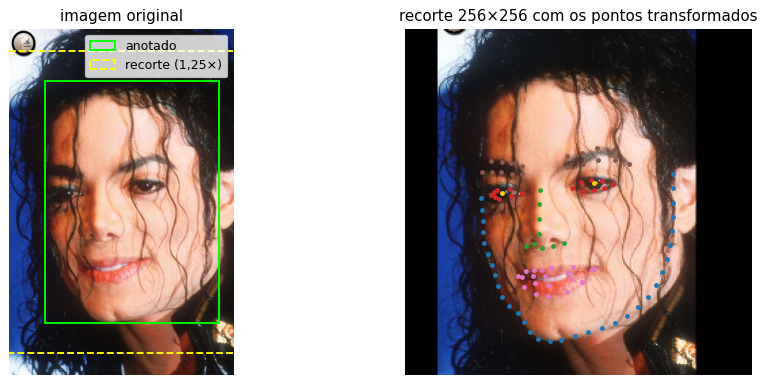

In [3]:
INPUT = 256        # lado da entrada do modelo
MARGIN = 1.25      # lado do recorte = 1,25 × maior lado do retângulo


def crop_matrix(box, size=INPUT, margin=MARGIN):
    # p' = s (p - c) + size/2 : mesmo centro do retângulo, lado = margin × maior lado
    x0, y0, x1, y1 = [float(v) for v in box]
    c = np.array([(x0 + x1) / 2, (y0 + y1) / 2])
    s = size / (margin * max(x1 - x0, y1 - y0))
    t = size / 2 - s * c
    return np.array([[s, 0, t[0]], [0, s, t[1]]])


def transform(points, m):
    return points @ m[:, :2].T + m[:, 2]


def crop(image, m, size=INPUT):
    return cv2.warpAffine(image, m, (size, size), flags=cv2.INTER_LINEAR, borderValue=0)


i = int(np.argmax((train["attr"].sum(1) == 0) * (train["box"][:, 2] - train["box"][:, 0])))
img, pts, box = load_rgb(train["image"][i]), train["landmarks"][i], train["box"][i]
m = crop_matrix(box)
face = crop(img, m)
p_crop = transform(pts.astype(np.float64), m)
p_back = transform(p_crop, cv2.invertAffineTransform(m))
print("ida e volta (imagem -> recorte -> imagem): erro máximo =", np.abs(p_back - pts).max(), "px")

x0, y0, x1, y1 = box
side = MARGIN * max(x1 - x0, y1 - y0)
cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img)
axes[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=1.5, label="anotado"))
axes[0].add_patch(plt.Rectangle((cx - side / 2, cy - side / 2), side, side, fill=False, ec="yellow",
                                lw=1.5, ls="--", label="recorte (1,25×)"))
axes[0].legend(); axes[0].set_title("imagem original"); axes[0].axis("off")
axes[1].imshow(face); draw_points(axes[1], p_crop, s=8)
axes[1].set_title("recorte 256×256 com os pontos transformados"); axes[1].axis("off")
plt.show()

## 2. Qual margem usar

Com uma margem pequena, o recorte corta o queixo e a testa. Com uma margem grande, a face fica
pequena e perdemos resolução. Para escolher, contamos em quantas faces todos os 98 pontos
ficam dentro do recorte.

In [4]:
def coverage(d, margin):
    inside = [((q >= 0) & (q <= INPUT - 1)).all()
              for q in (transform(p.astype(np.float64), crop_matrix(b, INPUT, margin))
                        for b, p in zip(d["box"], d["landmarks"]))]
    return 100 * np.mean(inside)


print("margem | faces do treino com os 98 pontos dentro do recorte")
for mg in [1.0, 1.1, 1.25, 1.4]:
    print(f"  {mg:.2f} | {coverage(train, mg):5.1f} %")

margem | faces do treino com os 98 pontos dentro do recorte
  1.00 |  34.6 %
  1.10 |  89.6 %
  1.25 |  99.0 %


  1.40 |  99.9 %


## 3. Quantos pixels sobram para os olhos

O que importa para a sonolência é a **abertura** do olho, que é uma distância pequena na
vertical. Vamos medir quantos pixels ela ocupa no recorte de 256.

In [5]:
train_crop_pts = np.stack([transform(p.astype(np.float64), crop_matrix(b))
                           for b, p in zip(train["box"], train["landmarks"])])
opening = (np.linalg.norm(train_crop_pts[:, 62] - train_crop_pts[:, 66], axis=1)
           + np.linalg.norm(train_crop_pts[:, 70] - train_crop_pts[:, 74], axis=1)) / 2
print(f"abertura do olho no recorte 256: mediana {np.median(opening):.1f} px | p10 {np.percentile(opening, 10):.1f} px")
for stride in [4, 8]:
    print(f"  heatmap {INPUT // stride}×{INPUT // stride}: a abertura mediana ocupa {np.median(opening) / stride:.1f} células")

abertura do olho no recorte 256: mediana 10.0 px | p10 5.5 px
  heatmap 64×64: a abertura mediana ocupa 2.5 células
  heatmap 32×32: a abertura mediana ocupa 1.3 células


Com mapas de calor de 64 por 64, a abertura típica do olho cabe em só duas ou três células.
Se o modelo escolhesse simplesmente a célula mais forte (o `argmax`), erraria até 2 pixels,
o que é cerca de 20 % da abertura do olho. Por isso o modelo vai usar o **soft-argmax**, que
calcula uma média ponderada e consegue posições entre as células (veja o `03_modelo`). Usar
entrada de 128 pixels deixaria o olho com uns 5 pixels, então descartamos essa opção.

## 4. Treino e validação

O teste oficial só é usado no final, no `05_avaliacao`. Para acompanhar o treino e escolher a
melhor época precisamos de uma validação, e ela sai do **treino oficial**: separamos 10 % das
**imagens** com uma semente fixa. Separar por imagem, e não por face, evita que duas pessoas da
mesma foto, com a mesma luz e a mesma câmera, caiam uma em cada lado.

In [6]:
def split_train_val(images, val_fraction=0.1, seed=SEED):
    unique = sorted(set(images))
    rng = np.random.default_rng(seed)
    val_images = set(rng.choice(unique, int(round(val_fraction * len(unique))), replace=False))
    is_val = np.array([im in val_images for im in images])
    return np.where(~is_val)[0], np.where(is_val)[0]


train_idx, val_idx = split_train_val(train["image"])
shared = set(train["image"][train_idx]) & set(train["image"][val_idx])
e = ear(train["landmarks"])
print(f"treino: {len(train_idx)} faces | validação: {len(val_idx)} faces | imagens nos dois lados: {len(shared)}")
print(f"EAR < 0,15 -> treino {100 * (e[train_idx] < 0.15).mean():.1f} % | validação {100 * (e[val_idx] < 0.15).mean():.1f} %")

treino: 6737 faces | validação: 763 faces | imagens nos dois lados: 0
EAR < 0,15 -> treino 8.9 % | validação 8.1 %


## 5. Data augmentation

As transformações usadas no treino são estas:

| Transformação | Faixa |
|---|---|
| Espelhamento horizontal | metade das vezes |
| Rotação | até 15 graus para cada lado |
| Escala do recorte | de 0,85 a 1,2 |
| Deslocamento | até 6 % do tamanho, em cada eixo |
| Contraste e brilho | contraste até 30 % e brilho até 15 % de 255, para mais ou para menos |

As transformações geométricas são juntadas numa **única matriz afim**, aplicada ao mesmo tempo
na imagem e nos pontos. Assim os pontos acompanham a imagem.

### O cuidado com o espelhamento

Espelhar a imagem troca cada x por `W − 1 − x`. Só que, depois disso, o ponto 60, que marcava o
olho **direito da pessoa**, passa a ficar em cima do olho **esquerdo**. Por isso, além de
espelhar, é preciso **trocar a ordem** dos pontos usando o `Mirror98.txt`, que diz qual índice
vira qual (o 60 vira 72, o 0 vira 32, e assim por diante).

60 -> 72 | 72 -> 60 | 0 -> 32 | 96 -> 97
espelhar duas vezes volta ao original: True


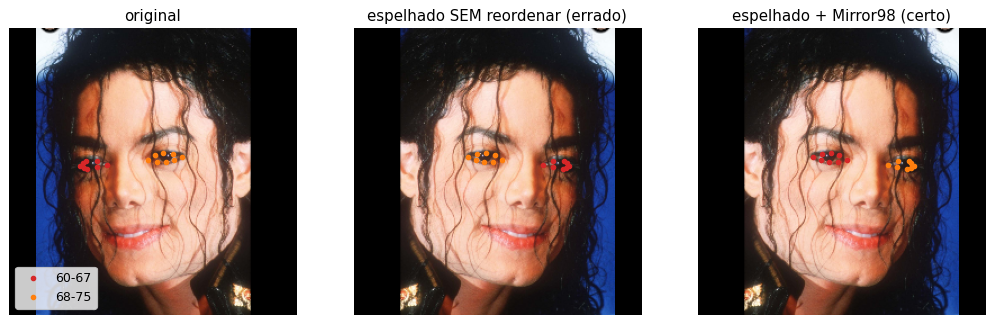

In [7]:
MIRROR = np.array((ANN / "Mirror98.txt").read_text().strip().split(","), dtype=int)
print("60 ->", MIRROR[60], "| 72 ->", MIRROR[72], "| 0 ->", MIRROR[0], "| 96 ->", MIRROR[96])
print("espelhar duas vezes volta ao original:", np.array_equal(MIRROR[MIRROR], np.arange(98)))


def flip(image, points, reorder=True):
    out = points.copy()
    out[:, 0] = image.shape[1] - 1 - points[:, 0]
    return image[:, ::-1], (out[MIRROR] if reorder else out)


fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, (title, im, q) in zip(axes, [
        ("original", face, p_crop),
        ("espelhado SEM reordenar (errado)", *flip(face, p_crop, reorder=False)),
        ("espelhado + Mirror98 (certo)", *flip(face, p_crop, reorder=True))]):
    ax.imshow(im)
    ax.scatter(q[60:68, 0], q[60:68, 1], s=12, c="tab:red", label="60-67")
    ax.scatter(q[68:76, 0], q[68:76, 1], s=12, c="tab:orange", label="68-75")
    ax.set_title(title); ax.axis("off")
axes[0].legend(loc="lower left")
plt.show()

Na figura do meio, os pontos 60 a 67 (em vermelho) foram parar do lado direito da imagem. Se
treinássemos assim, a rede receberia rótulos que se contradizem. Na figura da direita, com a
troca de ordem, eles continuam do lado esquerdo, como deveriam.

### Juntando tudo

A matriz final faz o recorte com uma escala sorteada, depois gira em torno do centro e por
fim desloca.

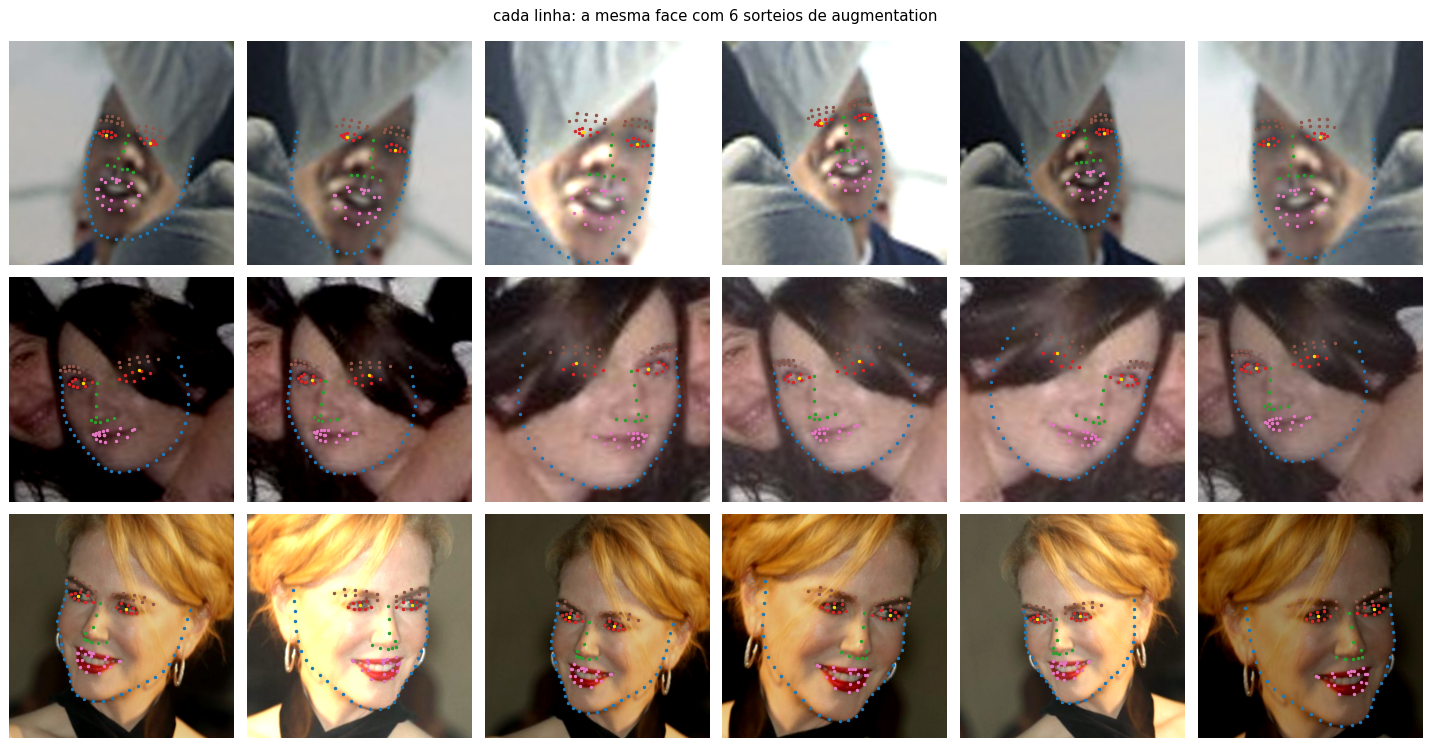

In [8]:
AUG = dict(flip_prob=0.5, rotation=15, scale=(0.85, 1.2), translation=0.06, color=0.3)


def augment(image, box, points, rng, aug=AUG, size=INPUT):
    scale = rng.uniform(*aug["scale"])
    m = crop_matrix(box, size, MARGIN * scale)            # escala > 1: face menor no recorte
    r = cv2.getRotationMatrix2D((size / 2, size / 2), rng.uniform(-aug["rotation"], aug["rotation"]), 1.0)
    r[:, 2] += rng.uniform(-aug["translation"], aug["translation"], 2) * size
    m = r @ np.vstack([m, [0, 0, 1]])                      # uma única matriz 2×3
    out, q = crop(image, m, size), transform(points.astype(np.float64), m)
    if rng.random() < aug["flip_prob"]:
        out, q = flip(out, q)
    c = aug["color"]
    alpha, beta = 1 + rng.uniform(-c, c), 255 * rng.uniform(-c, c) / 2   # contraste, brilho
    out = np.clip(out.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)
    return out, q


rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 6, figsize=(16, 8.5))
for row, k in zip(axes, rng.choice(train_idx, 3, replace=False)):
    im_k = load_rgb(train["image"][k])
    for ax in row:
        a_img, a_pts = augment(im_k, train["box"][k], train["landmarks"][k], rng)
        ax.imshow(a_img); draw_points(ax, a_pts, s=3); ax.axis("off")
plt.suptitle("cada linha: a mesma face com 6 sorteios de augmentation")
plt.tight_layout(); plt.show()

In [9]:
# verificação automática: o olho 60-67 continua do lado esquerdo da imagem?
def eye_order_ok(q):
    return q[60:68, 0].mean() < q[68:76, 0].mean()


rng = np.random.default_rng(1)
checked = swapped = 0
for k in rng.choice(train_idx, 1000, replace=False):
    if not eye_order_ok(train["landmarks"][k]):
        continue                       # perfil extremo: a ordem já é ambígua no original
    _, q = augment(load_rgb(train["image"][k]), train["box"][k], train["landmarks"][k], rng)
    checked += 1
    swapped += not eye_order_ok(q)
print(f"{checked} faces aumentadas verificadas | olhos trocados: {swapped}")

1000 faces aumentadas verificadas | olhos trocados: 0


## 6. Cache de recortes

Abrir a imagem inteira a cada época, com fotos de até 4.000 pixels, deixaria o treino muito
lento. Então salvamos **uma vez só** cada face como um recorte de **384 por 384 com margem de
1,875** (que é 1,25 vezes 1,5). Isso tem duas vantagens:

- os 256 pixels do centro são exatamente o recorte de entrada, com margem 1,25;
- a folga em volta dá espaço para girar, afastar e deslocar a face durante o treino sem
  aparecer borda preta.

Esse cache é a saída deste notebook, usada pelos próximos.

In [10]:
CACHE_SIZE, CACHE_MARGIN = 384, 1.875
PROCESSED.mkdir(parents=True, exist_ok=True)


def crop_face(args):
    rel, box = args
    m = crop_matrix(box, CACHE_SIZE, CACHE_MARGIN)
    return crop(load_rgb(rel), m, CACHE_SIZE), m


def build_cache(d, split):
    path = PROCESSED / f"{split}_crops.npy"
    if path.exists() and (PROCESSED / f"{split}_meta.npz").exists():
        print(split, "já existe:", path.relative_to(ROOT)); return
    images = np.lib.format.open_memmap(path, mode="w+", dtype=np.uint8,
                                       shape=(len(d["box"]), CACHE_SIZE, CACHE_SIZE, 3))
    matrices = np.zeros((len(d["box"]), 2, 3))
    with ThreadPoolExecutor(8) as pool:        # o OpenCV libera o GIL: threads bastam
        for k, (c, m) in enumerate(pool.map(crop_face, zip(d["image"], d["box"]))):
            images[k], matrices[k] = c, m
    images.flush()
    lm = np.stack([transform(p.astype(np.float64), m) for p, m in zip(d["landmarks"], matrices)])
    np.savez(PROCESSED / f"{split}_meta.npz", landmarks=lm.astype(np.float32),
             landmarks_orig=d["landmarks"], boxes=d["box"], attributes=d["attr"],
             matrices=matrices, images=d["image"])
    print(f"{split}: {len(d['box'])} recortes -> {path.stat().st_size / 1e9:.2f} GB")


build_cache(train, "train")
build_cache(test, "test")
np.savez(PROCESSED / "split.npz", train_idx=train_idx, val_idx=val_idx, seed=SEED)
print(sorted(p.name for p in PROCESSED.iterdir()))

train já existe: data/processed/train_crops.npy
test já existe: data/processed/test_crops.npy
['split.npz', 'test_crops.npy', 'test_meta.npz', 'train_crops.npy', 'train_meta.npz']


diferença média de pixel: 0.00 | diferença máxima nos pontos: 0.0000 px


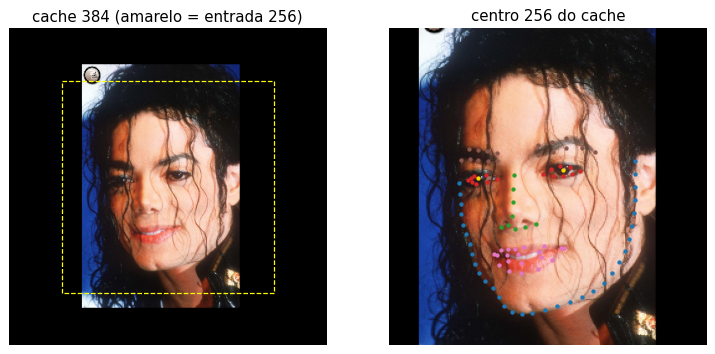

In [11]:
# conferência: o centro 256 do cache é o mesmo recorte feito direto da imagem
crops = np.load(PROCESSED / "train_crops.npy", mmap_mode="r")
meta = np.load(PROCESSED / "train_meta.npz")
off = (CACHE_SIZE - INPUT) // 2
center = np.asarray(crops[i])[off:off + INPUT, off:off + INPUT]
diff = np.abs(center.astype(int) - face.astype(int)).mean()
pts_center = meta["landmarks"][i] - off
print(f"diferença média de pixel: {diff:.2f} | diferença máxima nos pontos: {np.abs(pts_center - p_crop).max():.4f} px")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
axes[0].imshow(crops[i]); axes[0].add_patch(plt.Rectangle((off, off), INPUT, INPUT, fill=False, ec="yellow", ls="--"))
axes[0].set_title("cache 384 (amarelo = entrada 256)"); axes[0].axis("off")
axes[1].imshow(center); draw_points(axes[1], pts_center, s=6); axes[1].set_title("centro 256 do cache"); axes[1].axis("off")
plt.show()

A imagem e os pontos tirados do cache batem com o recorte feito direto da foto, então podemos
usar o cache no treino sem perder nada.

## Resumo das decisões

| Decisão | Valor | Por quê |
|---|---|---|
| Recorte | quadrado, mesmo centro, lado 1,25 vezes o maior lado | cobre cerca de 99 % das faces sem desperdiçar resolução |
| Entrada | 256 por 256 | o olho aberto fica com uns 10 pixels; com 128 seriam só 5 |
| Validação | 10 % das imagens do treino, semente 42 | nenhuma foto aparece dos dois lados |
| Augmentation | espelhamento com Mirror98, rotação de 15 graus, escala de 0,85 a 1,2, deslocamento de 6 % e cor | os pontos continuam corretos, conferido em 1.000 faces |
| Cache | recortes de 384 com margem 1,875 | treino rápido e folga para o augmentation |

No próximo notebook, `03_modelo.ipynb`, montamos a rede.